In [53]:
# importing packages
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import scipy as sp
import seaborn as sn
import warnings
warnings.simplefilter("ignore")

I'm curious how the minimum variance and maximum Sharpe ratio portfolios, discussed in 00, move over time. For this, data starting in 2013, 2018 and 2023 are selected.

In [54]:
symbols = ['SPY', 'IEFA', 'IEMG', 'AGG', 'GLD'] # Five ETFs, covering a variety of markets
n = len(symbols)
for symbol in symbols:
    info = yf.Ticker(symbol).info
    print(f"{symbol}: {info.get('longName', 'N/A')}")
raw_data2013 = yf.download(symbols, start = '2013-01-01')
raw_data2018 = yf.download(symbols, start = '2018-01-01')
raw_data2023 = yf.download(symbols, start = '2023-01-01')
data2013 = raw_data2013['Close']
data2018 = raw_data2018['Close']
data2023 = raw_data2023['Close']

datasets = {2013: data2013, 2018: data2018, 2023: data2023}

SPY: State Street SPDR S&P 500 ETF Trust
IEFA: iShares Core MSCI EAFE ETF
IEMG: iShares Core MSCI Emerging Markets ETF
AGG: iShares Core U.S. Aggregate Bond ETF
GLD: SPDR Gold Shares


[*********************100%***********************]  5 of 5 completed
[*********************100%***********************]  5 of 5 completed
[*********************100%***********************]  5 of 5 completed


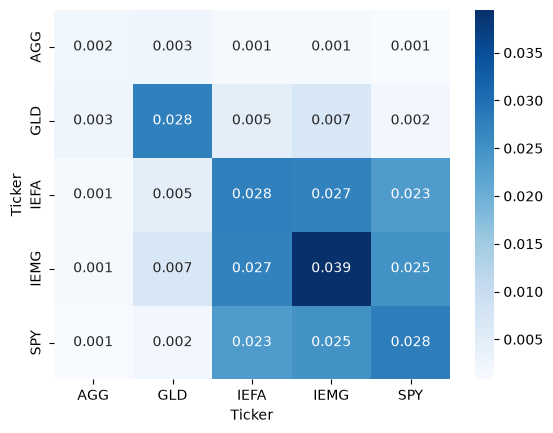

In [55]:
returns = {year: df.pct_change().dropna() for year, df in datasets.items()}
cov_matrix = {year: df.cov() * 252 for year, df in returns.items()} # Annualised
mean_returns = {year: df.mean() * 252 for year, df in returns.items()} # Annualised

sn.heatmap(cov_matrix[2013], annot=True, fmt='.3f', cmap='Blues')
plt.show()

In [59]:
random_weights = np.random.dirichlet(np.ones(n), size=10000).T # Dirichlet distribution to ensure weights sum to 1, while being random.

portfolio_returns = {year: random_weights.T @ mean_returns[year] for year, df in datasets.items()}
portfolio_variance = {year: np.diag(random_weights.T @ cov_matrix[year] @ random_weights) for year, df in datasets.items()}
portfolio_volatility = {year: np.sqrt(var) for year, var in portfolio_variance.items()}

In [60]:
rf = 0.0225 # ECB rate

wmv = {year: sp.optimize.minimize(lambda w: w.T @ cov_matrix[year] @ w, x0 = np.ones(n) / n, bounds=[(0, 1)] * n, constraints={'type': 'eq', 'fun': lambda w: np.sum(w) - 1}) for year in datasets}
wms = {year: sp.optimize.minimize(lambda w: -w.T @ (mean_returns[year] - rf) / (np.sqrt(w.T @ cov_matrix[year] @ w)), x0 = np.ones(n) / n, bounds=[(0, 1)] * n, constraints={'type': 'eq', 'fun': lambda w: np.sum(w) - 1}) for year in datasets}

wmv_return = {year: wmv[year].x.T @ mean_returns[year] for year in datasets}
wmv_volatility = {year: np.sqrt(wmv[year].x.T @ cov_matrix[year] @ wmv[year].x) for year in datasets}
wms_return = {year: wms[year].x.T @ mean_returns[year] for year in datasets}
wms_volatility = {year: np.sqrt(wms[year].x.T @ cov_matrix[year] @ wms[year].x) for year in datasets}

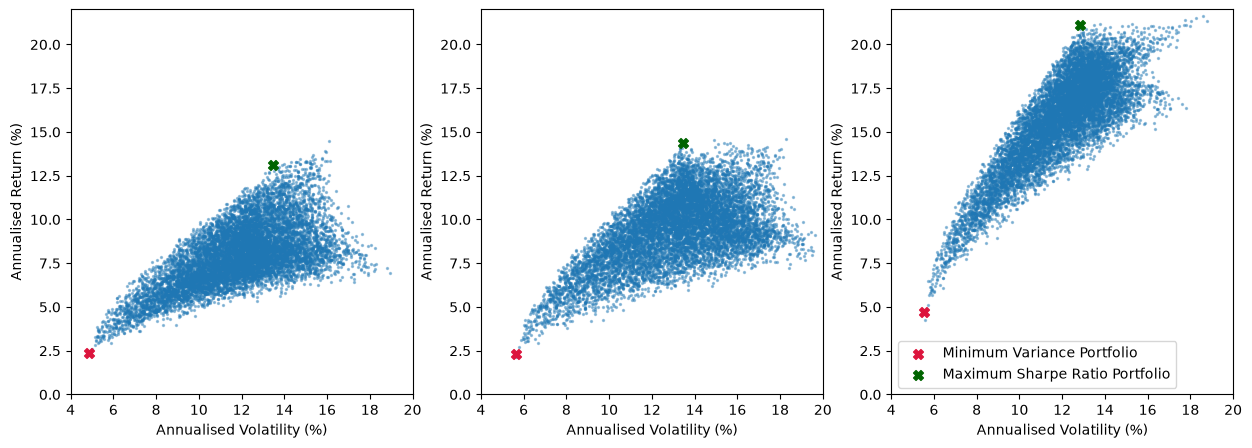

In [82]:
plt.figure(figsize=(15, 5))

for i, year in enumerate(datasets, start = 1):
    plt.subplot(1, 3, i)
    plt.scatter(portfolio_volatility[year] * 100, portfolio_returns[year] * 100, s=2, alpha=0.4)
    plt.scatter(wmv_volatility[year] * 100, wmv_return[year] * 100, s=50, c='crimson', marker='X', label='Minimum Variance Portfolio')
    plt.scatter(wms_volatility[year] * 100, wms_return[year] * 100, s=50, c='darkgreen', marker='X', label='Maximum Sharpe Ratio Portfolio')
    plt.xlim(4, 20)
    plt.ylim(0, 22)
    plt.xlabel('Annualised Volatility (%)')
    plt.ylabel('Annualised Return (%)')

plt.legend()
plt.show()